# 🗳️ Distribuição de Votos

Análise detalhada da distribuição de votos entre candidatos, partidos e tipos de voto.

**Gráficos incluídos:**
- Barras horizontais por candidato
- Pizza de share de votos
- Votos válidos vs brancos vs nulos
- Distribuição por partido/coligação
- Comparativo top 5

In [1]:

import json
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Find repo root and data dir robustly
def find_data_dir():
    candidates = [
        Path("../data"),
        Path("data"),
        Path("./data"),
        Path(__file__).parent / "../data" if '__file__' in globals() else None,
    ]
    # Also try from cwd
    cwd = Path.cwd()
    for p in [cwd / "data", cwd.parent / "data", cwd / "../data", Path("/home/user/eleicoes-data/data")]:
        candidates.append(p)
    for c in candidates:
        if c and c.exists() and list(c.glob("*.json")):
            return c
    # fallback: search recursively up to 3 levels
    for base in [Path.cwd(), Path.cwd().parent, Path("/home/user/eleicoes-data")]:
        for sub in [base, base / "eleicoes-data"]:
            d = sub / "data"
            if d.exists():
                return d
    return Path("../data")

DATA_DIR = find_data_dir()
print(f"📁 Data directory: {DATA_DIR.resolve()}")

files = sorted(DATA_DIR.glob("*.json"))
print(f"📊 Found {len(files)} snapshot files")
if files:
    print(f"   First: {files[0].name}")
    print(f"   Last:  {files[-1].name}")


def load_snapshot(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def extract_candidates(snapshot):
    """Flatten TSE payload into list of dicts."""
    rows = []
    payload = snapshot['data']
    for cargo in payload.get('carg', []):
        for agr in cargo.get('agr', []):
            for par in agr.get('par', []):
                for cand in par.get('cand', []):
                    rows.append({
                        'seq': cand.get('seq'),
                        'numero': cand.get('n'),
                        'nome_completo': cand.get('nm'),
                        'nome_urna': cand.get('nmu'),
                        'partido': par.get('sg'),
                        'partido_nome': par.get('nm'),
                        'agregacao': agr.get('nm'),
                        'votos': int(cand.get('vap', 0) or 0),
                        'percentual': float(str(cand.get('pvap', '0')).replace(',', '.') or 0),
                        'percentual_n': float(str(cand.get('pvapn', '0')).replace(',', '.') or 0),
                        'situacao': cand.get('st', ''),
                        'eleito': cand.get('e', ''),
                    })
    rows.sort(key=lambda x: x['votos'], reverse=True)
    return rows

def load_all_snapshots():
    all_data = []
    for fp in sorted(DATA_DIR.glob("*.json")):
        doc = load_snapshot(fp)
        meta = doc['metadata']
        data = doc['data']
        cands = extract_candidates(doc)
        # sections
        s = data.get('s', {})
        v = data.get('v', {})
        e = data.get('e', {})
        all_data.append({
            'file': fp.name,
            'path': fp,
            'scraped_at_utc': meta.get('scraped_at_utc'),
            'scraped_at_brasilia': meta.get('scraped_at_brasilia'),
            'tse_generated': meta.get('tse_file_generated_at'),
            'secoes_total': int(s.get('ts', 0) or 0),
            'secoes_apuradas': int(s.get('st', 0) or 0),
            'pct_apuradas': float(str(s.get('pst', '0')).replace(',', '.') or 0),
            'eleitorado': int(e.get('te', 0) or 0),
            'comparecimento': int(e.get('c', 0) or 0),
            'abstencao': int(e.get('a', 0) or 0),
            'votos_validos': int(v.get('vv', 0) or 0),
            'votos_brancos': int(v.get('vb', 0) or 0),
            'votos_nulos': int(v.get('vn', 0) or 0),
            'candidatos': cands,
            'metadata': meta,
            'raw': doc
        })
    return all_data

# Load once for convenience
all_snapshots = load_all_snapshots()
latest = all_snapshots[-1] if all_snapshots else None
if latest:
    print(f"✅ Latest snapshot: {latest['file']} | {latest['scraped_at_utc']}")
    print(f"   Seções: {latest['secoes_apuradas']}/{latest['secoes_total']} ({latest['pct_apuradas']}%)")


📁 Data directory: /home/user/eleicoes-data/data
📊 Found 43 snapshot files
   First: presidente_br_20261005_000211Z.json
   Last:  presidente_br_20261014_192215Z.json
✅ Latest snapshot: presidente_br_20261014_192215Z.json | 2026-10-14T19:22:15Z
   Seções: 499248/499248 (100.0%)


## 1. Dados Atuais - Preparação

In [2]:

df = pd.DataFrame(latest['candidatos'])
df['votos_milhoes'] = df['votos'] / 1_000_000
print(df[['nome_urna','partido','votos','percentual']].to_string(index=False))


                nome_urna   partido    votos  percentual
         FLAVIO BOLSONARO        PL 56104503       47.03
                     LULA        PT 53879538       45.16
    ESCRITOR AUGUSTO CURY    AVANTE  3448569        2.89
             RENAN SANTOS    MISSÃO  2675887        2.24
           RONALDO CAIADO       PSD  2605148        2.18
                     ZEMA      NOVO   326488        0.27
                   SAMARA        UP   122911        0.10
               HERTZ DIAS      PSTU    43103        0.04
           CLARIANA BARAO        DC    40043        0.03
           EDMILSON COSTA       PCB    22693        0.02
VETERINÁRIO WILSON GRASSI DEMOCRATA    16881        0.01
        RUI COSTA PIMENTA       PCO    15024        0.01


## 2. Gráfico de Barras - Todos os Candidatos

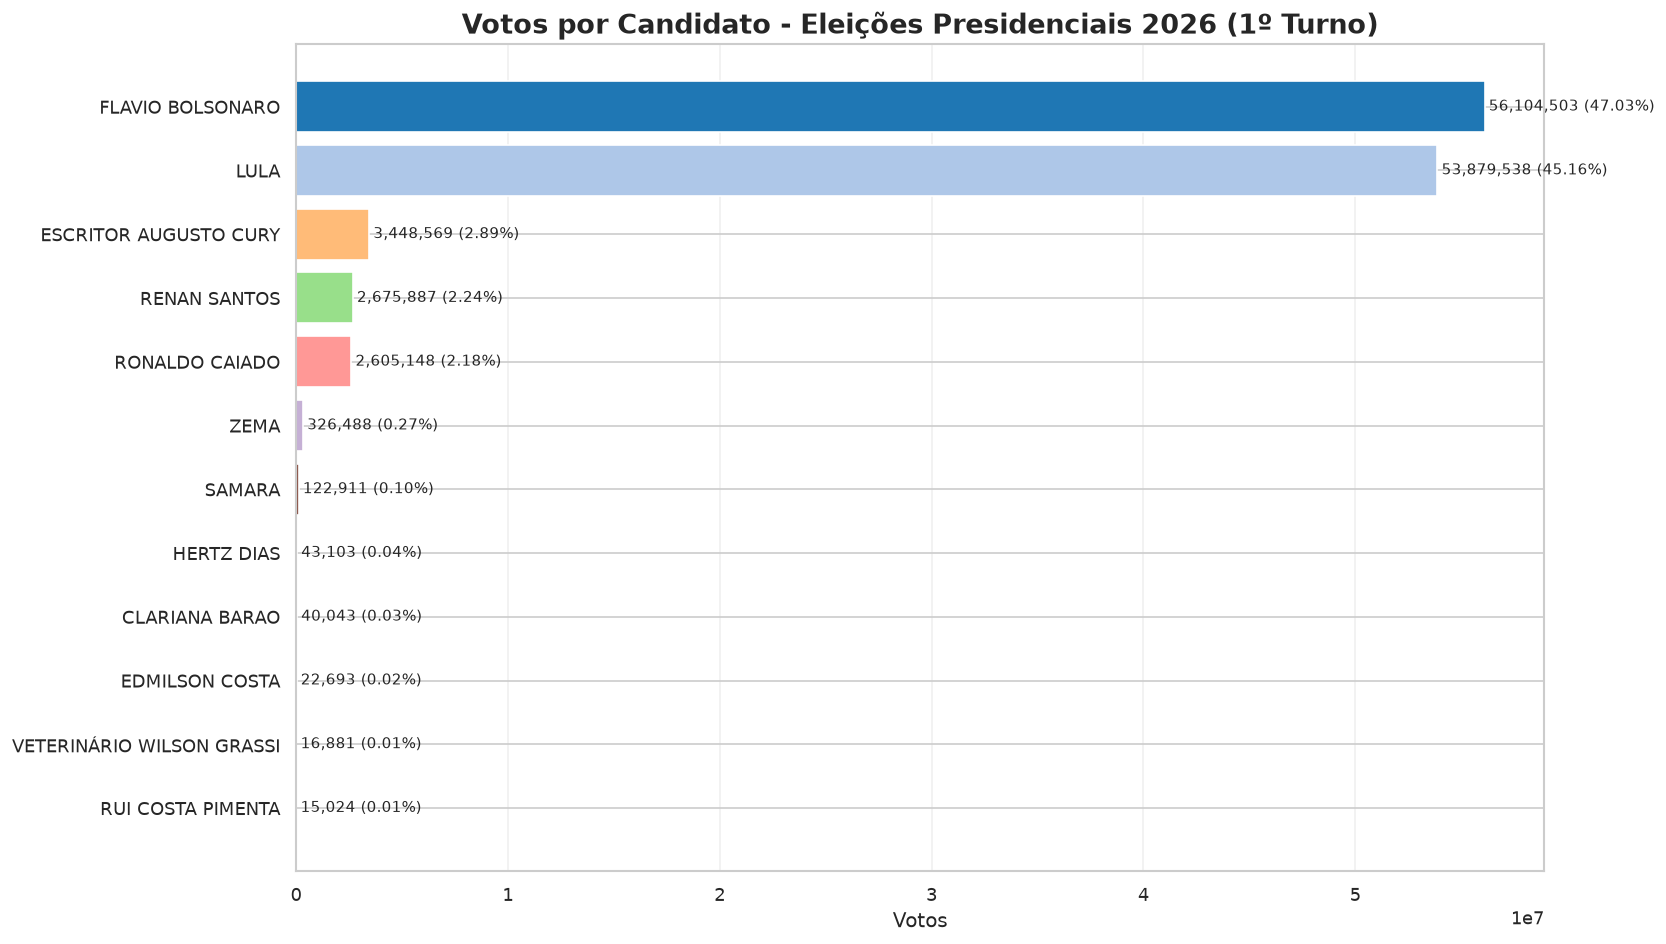

In [3]:

plt.figure(figsize=(14, 8))
colors = plt.cm.tab20(np.linspace(0, 1, len(df)))
bars = plt.barh(df['nome_urna'][::-1], df['votos'][::-1], color=colors[::-1])
plt.xlabel('Votos')
plt.title('Votos por Candidato - Eleições Presidenciais 2026 (1º Turno)', fontsize=16, fontweight='bold')
plt.grid(axis='x', alpha=0.3)

# Add value labels
for bar, votos, pct in zip(bars, df['votos'][::-1], df['percentual'][::-1]):
    plt.text(bar.get_width() + 200000, bar.get_y() + bar.get_height()/2, 
             f'{votos:,} ({pct:.2f}%)', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('vote_distribution_bar.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Gráfico de Pizza - Share de Votos Válidos

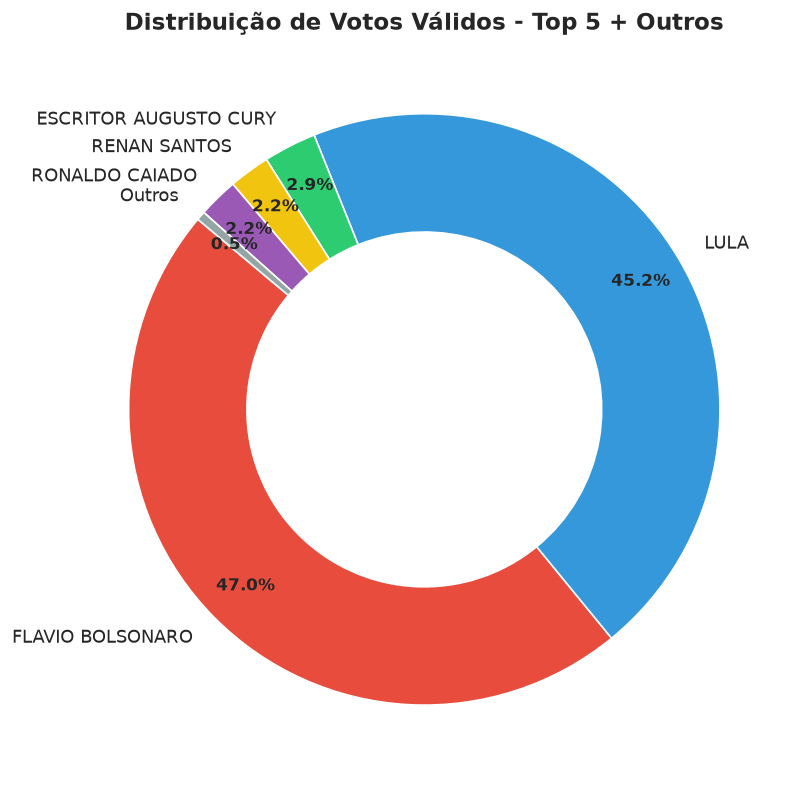

,nome_urna,votos,percentual
0,FLAVIO BOLSONARO,56104503,47.03
1,LULA,53879538,45.16
2,ESCRITOR AUGUSTO CURY,3448569,2.89
3,RENAN SANTOS,2675887,2.24
4,RONALDO CAIADO,2605148,2.18
5,Outros,587143,0.48


In [4]:

# Only top candidates get label, rest grouped as Outros
df_sorted = df.sort_values('votos', ascending=False)
top_n = 5
df_top = df_sorted.head(top_n)
df_outros = pd.DataFrame([{
    'nome_urna': 'Outros',
    'votos': df_sorted.iloc[top_n:]['votos'].sum(),
    'percentual': df_sorted.iloc[top_n:]['percentual'].sum()
}])
df_pie = pd.concat([df_top[['nome_urna','votos','percentual']], df_outros], ignore_index=True)

plt.figure(figsize=(10, 8))
colors_pie = ['#e74c3c', '#3498db', '#2ecc71', '#f1c40f', '#9b59b6', '#95a5a6']
wedges, texts, autotexts = plt.pie(df_pie['votos'], labels=df_pie['nome_urna'], autopct='%1.1f%%',
                                   colors=colors_pie, startangle=140, pctdistance=0.85,
                                   wedgeprops=dict(width=0.4, edgecolor='white'))
plt.setp(autotexts, size=10, weight="bold")
plt.title('Distribuição de Votos Válidos - Top 5 + Outros', fontsize=14, fontweight='bold')
plt.savefig('vote_distribution_pie.png', dpi=150, bbox_inches='tight')
plt.show()

df_pie


## 4. Votos Válidos, Brancos e Nulos

      Tipo  Quantidade  Percentual
0  Válidos   119300788   95.230487
1  Brancos     2300798    1.836586
2    Nulos     3669003    2.928740


/tmp/ipykernel_2024/3113335846.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_votos_tipo, x='Tipo', y='Quantidade', palette=['#2ecc71','#f1c40f','#e67e22'], ax=ax1)


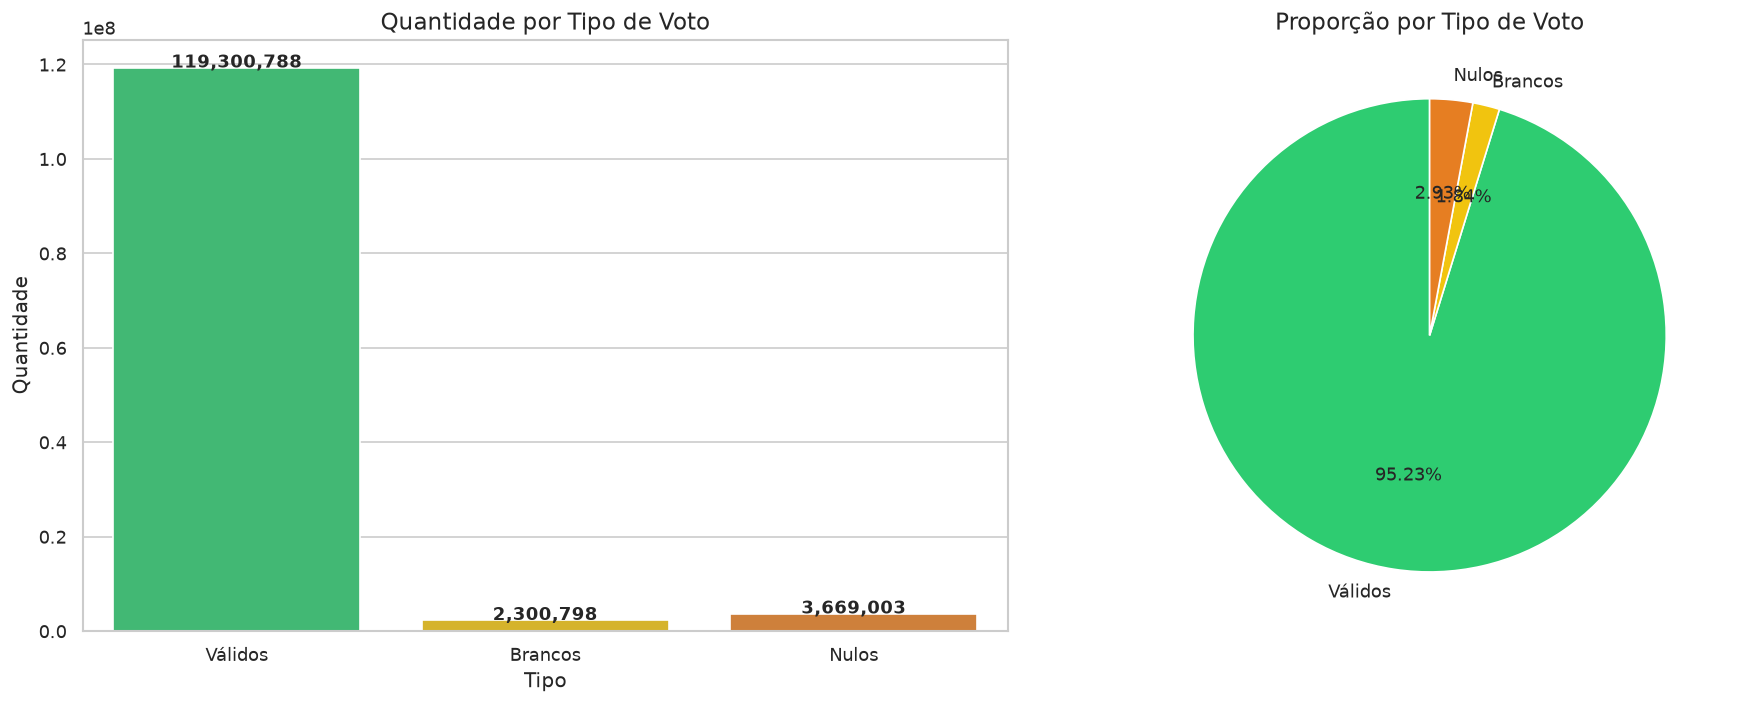

In [5]:

votos_data = {
    'Tipo': ['Válidos', 'Brancos', 'Nulos'],
    'Quantidade': [latest['votos_validos'], latest['votos_brancos'], latest['votos_nulos']],
    'Percentual': [
        latest['votos_validos']/latest['comparecimento']*100,
        latest['votos_brancos']/latest['comparecimento']*100,
        latest['votos_nulos']/latest['comparecimento']*100
    ]
}
df_votos_tipo = pd.DataFrame(votos_data)
print(df_votos_tipo)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Bar
sns.barplot(data=df_votos_tipo, x='Tipo', y='Quantidade', palette=['#2ecc71','#f1c40f','#e67e22'], ax=ax1)
ax1.set_title('Quantidade por Tipo de Voto')
for i, v in enumerate(df_votos_tipo['Quantidade']):
    ax1.text(i, v + 50000, f"{v:,}", ha='center', fontweight='bold')

# Pie
ax2.pie(df_votos_tipo['Quantidade'], labels=df_votos_tipo['Tipo'], autopct='%1.2f%%',
        colors=['#2ecc71','#f1c40f','#e67e22'], startangle=90)
ax2.set_title('Proporção por Tipo de Voto')

plt.tight_layout()
plt.savefig('vote_types.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Distribuição por Partido

      partido     votos  percentual
7          PL  56104503       47.03
10         PT  53879538       45.16
0      AVANTE   3448569        2.89
3      MISSÃO   2675887        2.24
8         PSD   2605148        2.18
4        NOVO    326488        0.27
11         UP    122911        0.10
9        PSTU     43103        0.04
1          DC     40043        0.03
5         PCB     22693        0.02
2   DEMOCRATA     16881        0.01
6         PCO     15024        0.01


/tmp/ipykernel_2024/1249498659.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_party, x='partido', y='votos', palette='viridis')


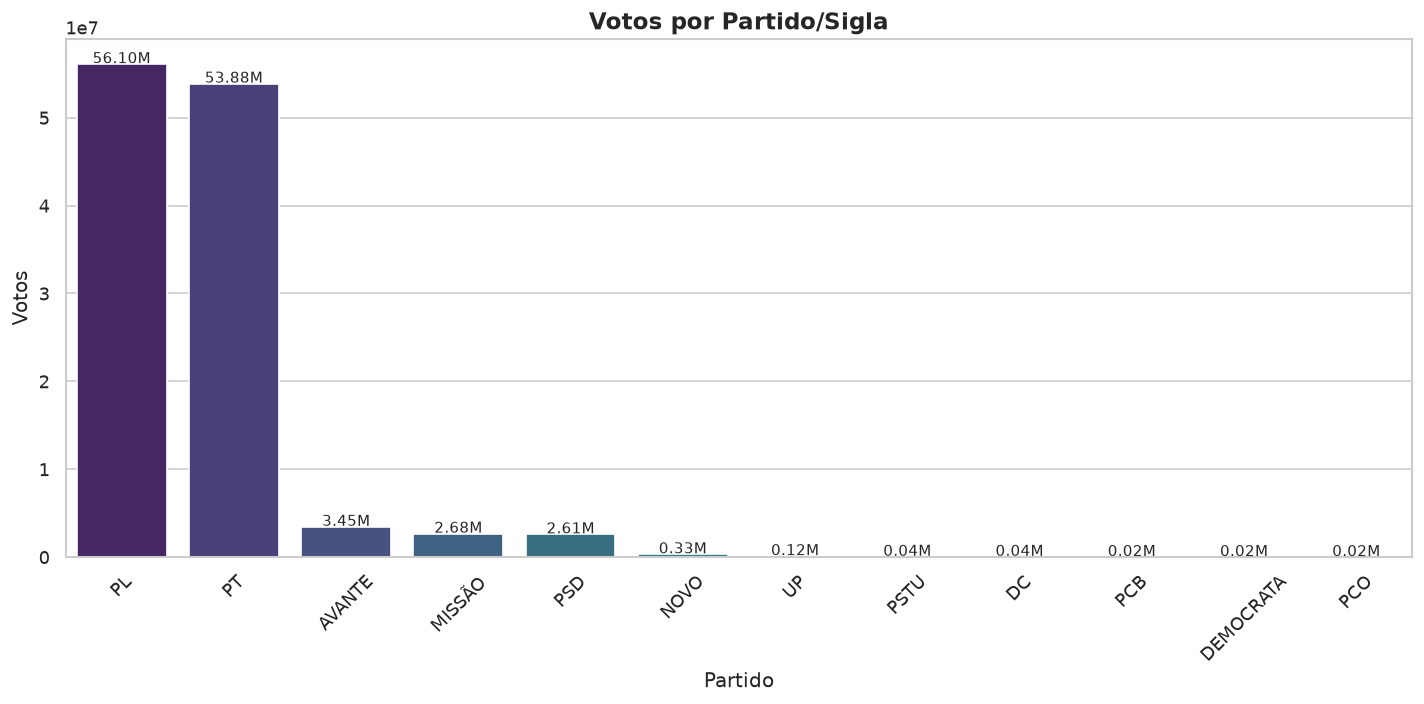

In [6]:

df_party = df.groupby('partido').agg({'votos':'sum','percentual':'sum'}).reset_index().sort_values('votos', ascending=False)
print(df_party)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_party, x='partido', y='votos', palette='viridis')
plt.title('Votos por Partido/Sigla', fontweight='bold')
plt.ylabel('Votos')
plt.xlabel('Partido')
plt.xticks(rotation=45)
for i, v in enumerate(df_party['votos']):
    plt.text(i, v + 100000, f"{v/1e6:.2f}M", ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('vote_by_party.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Comparativo Top 2 - Segundo Turno?

1º: FLAVIO BOLSONARO - 56,104,503 (47.03%)
2º: LULA - 53,879,538 (45.16%)
Diferença: 2,224,965 votos
Soma top2: 109,984,041 (92.19% dos válidos)


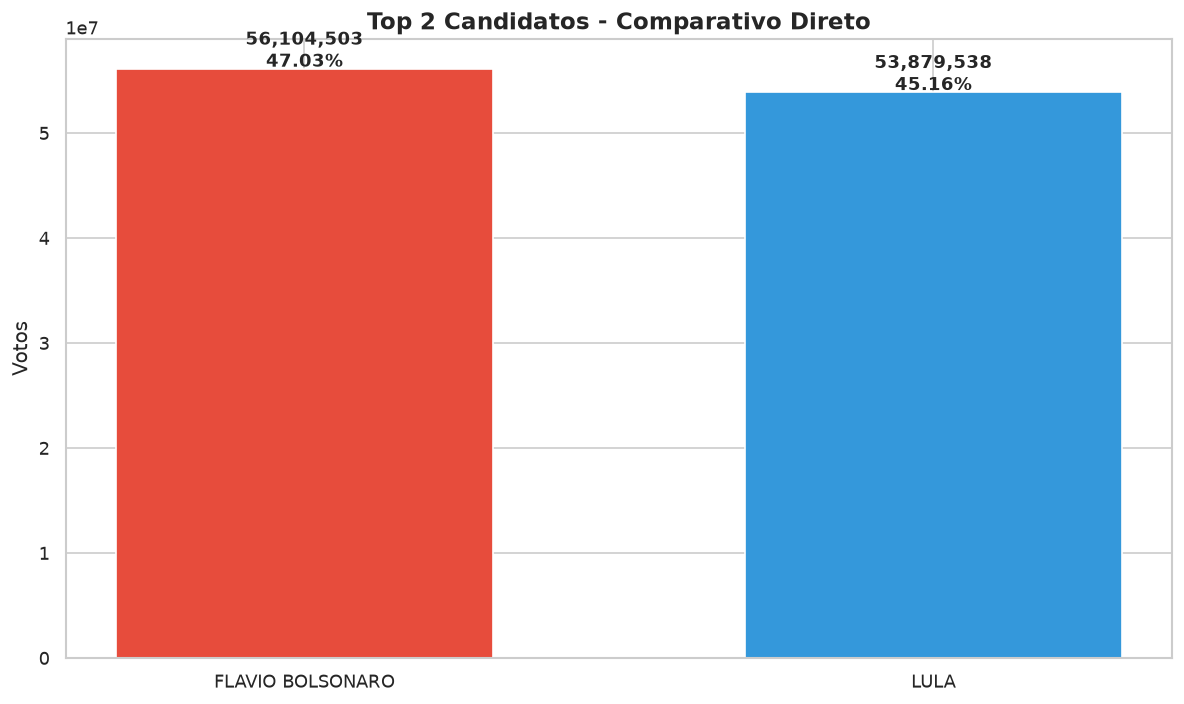

In [7]:

top2 = df.head(2)
print(f"1º: {top2.iloc[0]['nome_urna']} - {top2.iloc[0]['votos']:,} ({top2.iloc[0]['percentual']:.2f}%)")
print(f"2º: {top2.iloc[1]['nome_urna']} - {top2.iloc[1]['votos']:,} ({top2.iloc[1]['percentual']:.2f}%)")
print(f"Diferença: {top2.iloc[0]['votos'] - top2.iloc[1]['votos']:,} votos")
print(f"Soma top2: {top2['votos'].sum():,} ({top2['percentual'].sum():.2f}% dos válidos)")

plt.figure(figsize=(10, 6))
bars = plt.bar(top2['nome_urna'], top2['votos'], color=['#e74c3c','#3498db'], width=0.6)
plt.title('Top 2 Candidatos - Comparativo Direto', fontsize=14, fontweight='bold')
plt.ylabel('Votos')
for bar, votos, pct in zip(bars, top2['votos'], top2['percentual']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200000,
             f"{votos:,}\n{pct:.2f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('top2_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
